# Multimodal Music Analysis

The target of this project is the implementation of a complete pipeline for extracting knowledge from music data by combining two different modalities: **Audio** and **Text**. The project is split into two parts:  
1. Preprocessing of the data, generation of embeddings and researching analysis.
2. Classification, Fusion and Evaluation.  
  
This notebook contains the implementation of part 1.


Requirements:

In [ ]:
%pip install seaborn
%pip install datasets
%pip install matplotlib
%pip install vaderSentiment
%pip install kneed
%pip install contractions
%pip install pyspellchecker
%pip install scikit-learn
%pip install pandas
%pip install wordcloud

## 1. Data Collection


In [1]:
import pandas as pd
import os

- Run the code in the next sections for pre-processing the data 
- In case the file already exists, the next sections are skipped automatically

In [9]:
def keep_top_n(df, column, n):
    top_values = df[column].value_counts().head(n).index.to_list()
    filtered_df = df[df[column].isin(top_values)]
    return filtered_df

In [10]:
def create_lyrics_df(target_ids, path='data/processed_lyrics'):
    # --- Filtering the lyrics of the songs ---
    lyrics_folder = path

    lyrics_data = []

    for filename in os.listdir(lyrics_folder):
        if filename.endswith('.txt'):
            song_id = filename.replace('.txt', '')
            
            if song_id in target_ids:
                file_path = os.path.join(lyrics_folder, filename)
                
                with open(file_path, 'r', encoding='utf-8') as f:
                    lyrics_text = f.read()
                
                lyrics_data.append({
                    'id': song_id,
                    'lyrics': lyrics_text
                })

    lyrics_df = pd.DataFrame(lyrics_data)
    return lyrics_df

In [11]:
def merge_dataframes(dfs, merge_on):
    merged_df = dfs[0]

    for df in dfs[1:]:
        merged_df = pd.merge(merged_df, df, on=merge_on)

    return merged_df


In [12]:

def collect_data():
    # --- Importing the datasets ---
    genres_df = pd.read_csv('data/id_genres.csv', sep='\t') 
    information_df = pd.read_csv('data/id_information.csv', sep='\t')
    tags_df = pd.read_csv('data/id_tags.csv', sep='\t')
    mfcc_stats_df = pd.read_csv('data/id_mfcc_stats.tsv', sep='\t').dropna()

    # ---- Group mfcc stats in one column for better data ----
    mfcc_stats_df = mfcc_stats_df.copy()
    
    mfcc_columns = [col for col in mfcc_stats_df.columns if 'mfcc' in col.lower() or 'cov' in col.lower()]
    mfcc_stats_df['audio_stats'] = mfcc_stats_df[mfcc_columns].to_dict(orient='records')
    audio_stats_df = mfcc_stats_df.drop(columns=mfcc_columns)

    # --- Filtering the genres dataset to only include the top n most common genres ---
    filtered_genres_df = keep_top_n(genres_df, "genres", 5)

    # --- Create dataframe with the lyrics of the songs ---
    lyrics_df = create_lyrics_df(target_ids=set(filtered_genres_df['id'].astype(str)))

    # --- Merging dataframes ---
    dataframes = [filtered_genres_df, information_df, tags_df, audio_stats_df, lyrics_df]
    df = merge_dataframes(dataframes, "id")

    # --- Handling missing and duplicate values ---
    df = df[df['lyrics'].notna()]
    df = df[df['lyrics'].str.strip() != '']
    df = df[df['genres'].notna()]
    df = df[df['genres'].str.strip() != '']
    df = df.drop_duplicates(subset='id', keep='first')

    return df
    

In [17]:
final_df_path = "data/final_data.csv"
if (os.path.isfile(path=final_df_path)):
    data = pd.read_csv(final_df_path,)
else:
    data = collect_data()
    data = data.drop(columns=["artist", "album_name"])
    data.to_csv(final_df_path, index=False)
    
data.head()

,id,genres,song,tags,audio_stats,lyrics
0,0009fFIM1eYThaPg,pop,Rain on Me,"pop,british,female vocalists,dance,cheryl cole","{'MFCC000': 23.622419357299805, 'MFCC001': -14...",sunni day get nowher hide cloud sky pretend ge...
1,00P2bHdWFkghmDqz,soul,Tell Me a Tale,"fip,soul","{'MFCC000': 23.64550018310547, 'MFCC001': -2.0...",tell tale alway sing song alway tell stori rea...
2,00XWljDxNBgBKEEA,pop,Y cómo es él?,"jose luis perales,spanish,pop","{'MFCC000': 21.851207733154297, 'MFCC001': -14...",look eye would swear someth new tell start wom...
3,00b6fV3nx5z2b8Ls,pop,ABC,"glee,pop,cover,glee cast","{'MFCC000': 23.93406867980957, 'MFCC001': -16....",buhbuh buh buhbuh buhbuh buh buhbuh go school ...
4,013QDoTqbexEwkHr,pop,Patience,"pop,george michael,6 of 10 stars","{'MFCC000': 20.773107528686523, 'MFCC001': 0.3...",like convers noon stop breath imagin god alrea...


## 2. Feature Extraction

## 3. Visualization and Analysis

In [29]:
wordcloud_df = data[['genres','tags']]
rap_df = wordcloud_df[wordcloud_df['genres'] == 'rap']
rock_df = wordcloud_df[wordcloud_df['genres'] == 'rock'] 


rap_tags = " ".join(rap_df['tags'].dropna())
rock_tags = " ".join(rock_df['tags'].dropna())

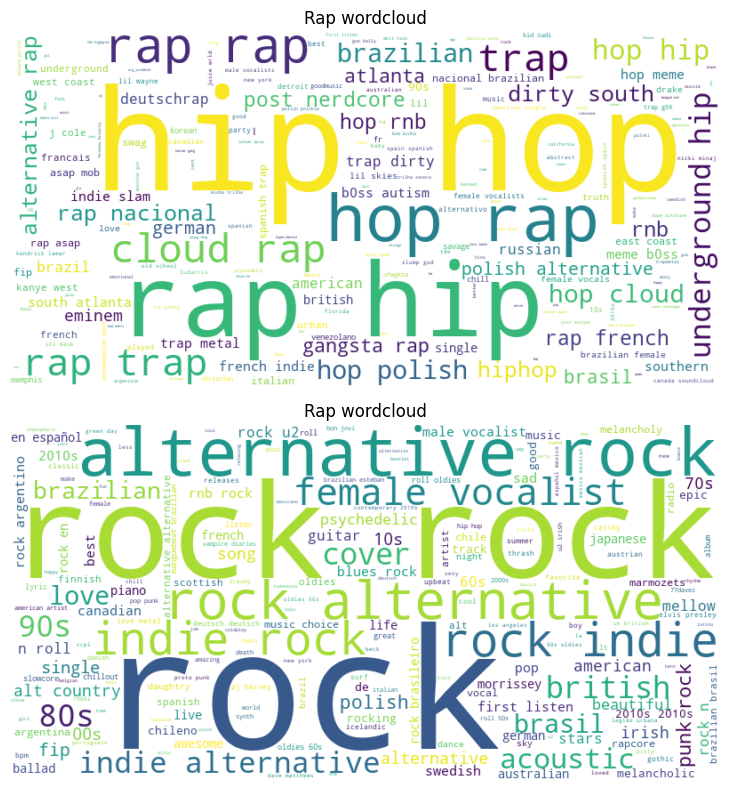

In [34]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

wordcloud_rap = WordCloud(width=800, height=400, background_color='white').generate(rap_tags)
wordcloud_rock = WordCloud(width=800, height=400, background_color='white').generate(rock_tags)


fig, ax = plt.subplots(2, 1, figsize=(20,8))
ax[0].imshow(wordcloud_rap, interpolation="bilinear")
ax[0].set_title("Rap wordcloud")
ax[0].axis("off")

ax[1].imshow(wordcloud_rock, interpolation="bilinear")
ax[1].set_title("Rap wordcloud")
ax[1].axis("off")
plt.tight_layout()
plt.show()
